<a href="https://colab.research.google.com/github/Divyasharma1910/Image_processing/blob/main/Assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files


Saving space.jpg to space.jpg


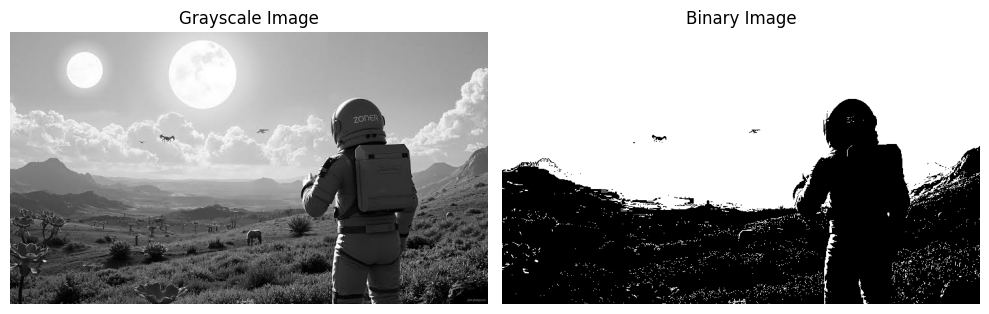

In [2]:

uploaded = files.upload()

image_path = next(iter(uploaded))

# Read image as grayscale
gray_image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if gray_image is None:
    raise ValueError("Could not read image. Please upload a valid image.")

# Convert grayscale image to binary image
threshold_value = 127
_, binary_image = cv2.threshold(
    gray_image, threshold_value, 255, cv2.THRESH_BINARY
)

# Display both images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_image, cmap="gray", vmin=0, vmax=255)
plt.title("Binary Image")
plt.axis("off")

plt.tight_layout()
plt.show()


Enter border width in pixels: 20
Enter border color (0-255): 0


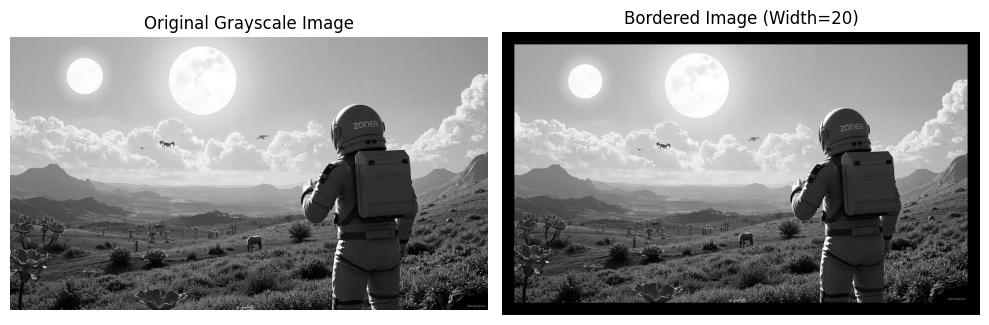

In [3]:

# Input border width and grayscale color
border_width = int(input("Enter border width in pixels: "))
border_color = int(input("Enter border color (0-255): "))

if border_width < 0:
    raise ValueError("Border width cannot be negative.")

if not 0 <= border_color <= 255:
    raise ValueError("Border color must be between 0 and 255.")

# Add border to grayscale image
gray_bordered = cv2.copyMakeBorder(
    gray_image,
    border_width, border_width,
    border_width, border_width,
    cv2.BORDER_CONSTANT,
    value=border_color
)

# Display result
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_bordered, cmap="gray", vmin=0, vmax=255)
plt.title(f"Bordered Image (Width={border_width})")
plt.axis("off")

plt.tight_layout()
plt.show()


Enter border width in pixels: 20
Enter border color (0=black, 255=white): 255


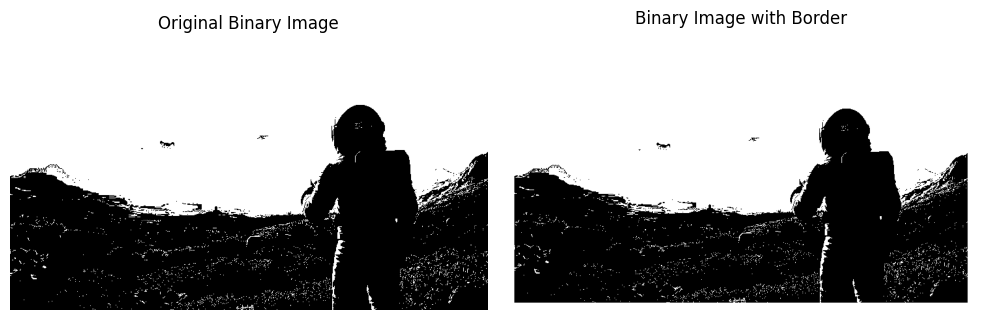

In [4]:

# Input border width and binary border color
binary_border_width = int(input("Enter border width in pixels: "))
binary_border_color = int(
    input("Enter border color (0=black, 255=white): ")
)

if binary_border_width < 0:
    raise ValueError("Border width cannot be negative.")

if binary_border_color not in (0, 255):
    raise ValueError("For a binary image, enter 0 or 255.")

# Add border to binary image
binary_bordered = cv2.copyMakeBorder(
    binary_image,
    binary_border_width, binary_border_width,
    binary_border_width, binary_border_width,
    cv2.BORDER_CONSTANT,
    value=binary_border_color
)

# Display result
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(binary_image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Binary Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_bordered, cmap="gray", vmin=0, vmax=255)
plt.title("Binary Image with Border")
plt.axis("off")

plt.tight_layout()
plt.show()


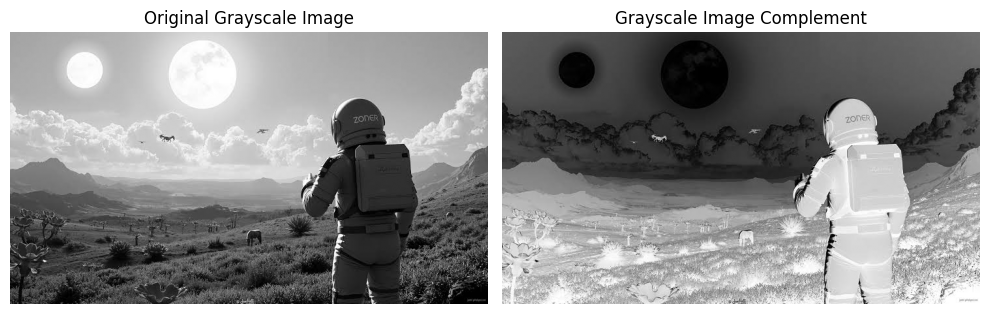

In [5]:

# Calculate grayscale image complement
gray_complement = 255 - gray_image

# Display original and complemented images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_complement, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale Image Complement")
plt.axis("off")

plt.tight_layout()
plt.show()


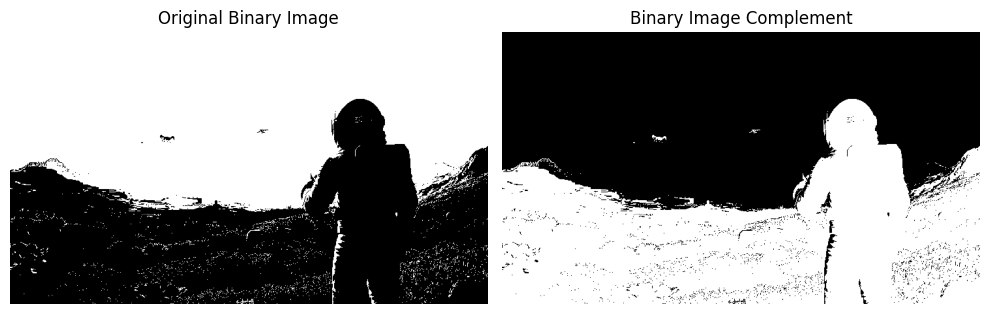

In [6]:

# Calculate binary image complement
binary_complement = 255 - binary_image

# Display original and complemented images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(binary_image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Binary Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_complement, cmap="gray", vmin=0, vmax=255)
plt.title("Binary Image Complement")
plt.axis("off")

plt.tight_layout()
plt.show()


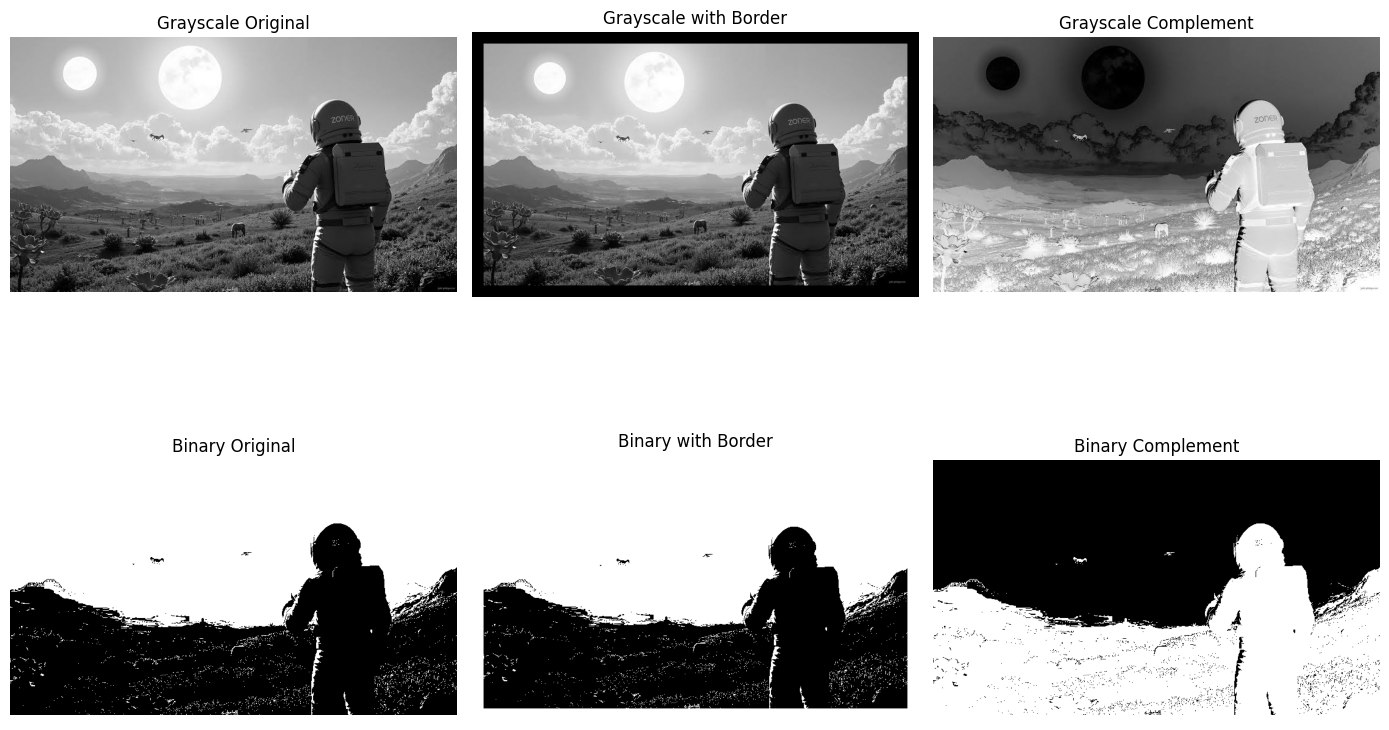

In [7]:

# Compare all results in one figure
results = [
    ("Grayscale Original", gray_image),
    ("Grayscale with Border", gray_bordered),
    ("Grayscale Complement", gray_complement),
    ("Binary Original", binary_image),
    ("Binary with Border", binary_bordered),
    ("Binary Complement", binary_complement)
]

plt.figure(figsize=(14, 10))

for i, (title, result) in enumerate(results):
    plt.subplot(2, 3, i + 1)
    plt.imshow(result, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [8]:

import zipfile

output_images = {
    "grayscale_bordered.png": gray_bordered,
    "binary_bordered.png": binary_bordered,
    "grayscale_complement.png": gray_complement,
    "binary_complement.png": binary_complement
}

with zipfile.ZipFile("Assignment_3_Results.zip", "w") as z:
    for filename, result in output_images.items():
        cv2.imwrite(filename, result)
        z.write(filename)

print("All results saved successfully!")
files.download("Assignment_3_Results.zip")


All results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>